Importa as bibliotecas necessárias e lê o arquivo de dados.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

arquivo = "dados.xlsx"
df = pd.read_excel(arquivo)
df.head()


,ID_Ensaio,Data_Hora,Tipo_Motor,Estrategia_Controle,Inversor,Nivel_Carga,Ganho_Kp,Ganho_Ki,Setpoint_Rotacao_rpm,Rotacao_Medida_rpm,Erro_Rotacao_rpm,Tensao_Linha_V,Corrente_A,Potencia_Ativa_kW,Fator_Potencia,THD_Corrente_Perc,Temperatura_Enrolamento_C,Vibracao_mm_s,Tempo_Resposta_ms,Status_Alarme
0,EN-00001,2025-05-22 06:19:00,Síncrono PM,Controle vetorial,Inversor B,Leve,1.371,0.542,1800,1771.4,-28.6,389.5,7.20,4.17,0.858,7.20,59.5,2.07,87.1,Normal
1,EN-00002,2025-07-23 16:21:00,Relutância síncrona,Controle vetorial,Inversor B,Pesada,1.775,0.610,2400,2385.1,-14.9,382.7,19.30,12.24,0.957,5.42,83.4,2.15,119.4,Normal
2,EN-00003,2025-03-15 13:20:00,Indução trifásico,Controle vetorial,Inversor B,Pesada,1.406,0.587,900,884.2,-15.8,364.6,11.14,6.32,0.899,5.39,84.9,3.03,106.4,Normal
3,EN-00004,2025-09-29 15:55:00,Síncrono PM,DTC,Inversor A,Sobrecarga,2.036,0.586,1500,1492.5,-7.5,397.1,17.65,12.02,0.990,5.86,93.3,2.29,59.7,Alerta
4,EN-00005,2025-12-31 19:12:00,Indução trifásico,Controle vetorial,Inversor B,Média,1.530,0.604,1800,1789.8,-10.2,368.6,12.91,6.87,0.834,7.32,66.8,2.37,134.4,Normal


Seleciona a coluna de temperatura do enrolamento e descreve estatísticas gerais.


In [ ]:
temperatura = df['Temperatura_Enrolamento_C']
temperatura.describe()


count    1050.000000
mean       76.248667
std        13.356535
min        42.600000
25%        66.700000
50%        75.600000
75%        86.300000
max       116.900000
Name: Temperatura_Enrolamento_C, dtype: float64

Os valores de temperatura foram agrupados em classes para facilitar a visualização. A tabela abaixo reúne a frequência absoluta, a frequência absoluta acumulada, a frequência percentual e a frequência percentual acumulada.


In [ ]:
bins = [42.5, 50, 60, 70, 80, 90, 100, 110, 120]
freq_abs = pd.cut(temperatura, bins).value_counts().sort_index()
freq_abs.name = 'Frequência Absoluta'

freq_abs_acumulada = freq_abs.cumsum()
freq_percentual = (freq_abs / freq_abs.sum()) * 100
freq_percentual_acumulada = freq_percentual.cumsum()

tabela_freq = pd.DataFrame({
    'Frequência Absoluta': freq_abs,
    'Frequência Absoluta Acumulada': freq_abs_acumulada,
    'Frequência Percentual (%)': freq_percentual.round(2),
    'Frequência Percentual Acumulada (%)': freq_percentual_acumulada.round(2)
})

tabela_freq


,Frequência Absoluta,Frequência Absoluta Acumulada,Frequência Percentual (%),Frequência Percentual Acumulada (%)
Temperatura_Enrolamento_C,,,,
"(42.5, 50.0]",12,12,1.14,1.14
"(50.0, 60.0]",113,125,10.76,11.90
"(60.0, 70.0]",246,371,23.43,35.33
"(70.0, 80.0]",255,626,24.29,59.62
"(80.0, 90.0]",252,878,24.00,83.62
"(90.0, 100.0]",133,1011,12.67,96.29
"(100.0, 110.0]",38,1049,3.62,99.90
"(110.0, 120.0]",1,1050,0.10,100.00


Gráfico de barras da frequência absoluta e da frequência percentual por classe de temperatura, com título e eixos identificados.


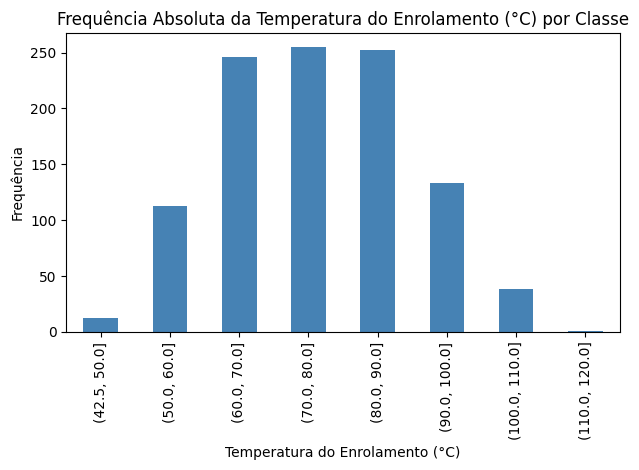

In [ ]:
tabela_freq['Frequência Absoluta'].plot(kind='bar', color='steelblue')
plt.title('Frequência Absoluta da Temperatura do Enrolamento (°C) por Classe')
plt.xlabel('Temperatura do Enrolamento (°C)')
plt.ylabel('Frequência')
plt.tight_layout()
plt.show()


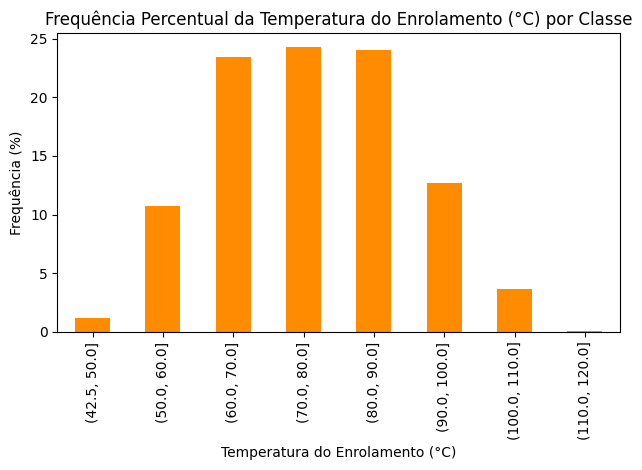

In [ ]:
tabela_freq['Frequência Percentual (%)'].plot(kind='bar', color='darkorange')
plt.title('Frequência Percentual da Temperatura do Enrolamento (°C) por Classe')
plt.xlabel('Temperatura do Enrolamento (°C)')
plt.ylabel('Frequência (%)')
plt.tight_layout()
plt.show()


Cálculo das principais medidas de tendência central para a variável Temperatura do Enrolamento.


In [ ]:
media = df['Temperatura_Enrolamento_C'].mean()
mediana = df['Temperatura_Enrolamento_C'].median()
moda = df['Temperatura_Enrolamento_C'].mode()

print(f'Média: {media:.2f} °C')
print(f'Mediana: {mediana:.2f} °C')
print('Moda:')
display(moda)


Média: 76.25 °C
Mediana: 75.60 °C
Moda:


0    81.5
Name: Temperatura_Enrolamento_C, dtype: float64

**Interpretação:** a temperatura média do enrolamento nos ensaios é de aproximadamente **76,25 °C**, muito próxima da mediana de **75,60 °C**, o que indica uma distribuição praticamente simétrica em torno do valor central, sem grande influência de valores extremos. A moda é **81,5 °C**, o valor de temperatura que mais se repete entre os 1.050 ensaios. O fato de média, mediana e moda estarem relativamente próximas reforça que a maior parte dos motores opera dentro de uma faixa de temperatura considerada normal, com poucos ensaios em condições de aquecimento extremo (a tabela de frequências mostra que apenas uma pequena parcela dos registros ultrapassa 100 °C).
